# Model 2 – 03 Compare Models + Ensemble
**Purpose:** Train EfficientNetV2-S (CNN) and DeiT-Small (vision transformer) with the SAME data, augmentation and
settings as MobileNetV3 (02), compare all three on the same test set, then ensemble the best two (chosen on validation).
**Inputs:** outputs/model2/manifest_split.csv, cache_224.npz, preds_mobilenetv3_{val,test}.csv
**Outputs:** outputs/model2/{name}_model2_best.pt, preds_{name}_{val,test}.csv, info_{name}.json, comparison table

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model2'
MANIFEST   = OUT_DIR / 'manifest_split.csv'
CACHE      = OUT_DIR / 'cache_224.npz'

SEED, IMG_SIZE, BATCH_SIZE = 42, 224, 64
EPOCHS, LR, PATIENCE = 15, 1e-4, 4
P_LOWRES, P_JPEG = 0.3, 0.3

# name used in file names  ->  pretrained model from the timm library
MODELS = {
    'efficientnetv2_s': 'tf_efficientnetv2_s.in21k_ft_in1k',   # CNN, ~20M parameters
    'deit_small':       'deit_small_patch16_224.fb_in1k',      # vision transformer, ~22M parameters
}

In [2]:
!pip install -q timm
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, torch, random, timm, time, os, io, json
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '| timm', timm.__version__)

df = pd.read_csv(MANIFEST)
cache = np.load(CACHE, allow_pickle=True)
X = cache['images']
assert (cache['paths'][df.cache_idx] == df.path).all(), 'Manifest and cache do not match!'
print('Manifest:', df.shape, ' Cache:', X.shape)

Mounted at /content/drive
Device: cuda | timm 1.0.30
Manifest: (3682, 14)  Cache: (3712, 224, 224)


In [3]:
CLASSES = sorted(df['label'].unique())
SHORT = {c: c.split(' - ')[0] for c in CLASSES}
SUPER = {c: ('OTHER' if c == 'OTHER' else
             'LEG' if SHORT[c] in ('Hip to knee', 'Knee to ankle', 'Foot and ankle') else 'HAND') for c in CLASSES}
SUPER_NAMES = ['HAND', 'LEG', 'OTHER']
M = np.array([[SUPER[c] == s for s in SUPER_NAMES] for c in CLASSES], dtype=float)   # 7 -> 3 mapping
df['y'] = df['label'].map({c: i for i, c in enumerate(CLASSES)})
splits = {s: df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test']}
print({s: len(f) for s, f in splits.items()})

{'train': 2638, 'val': 525, 'test': 519}


In [4]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

def degrade(img):
    if random.random() < P_LOWRES:
        s = random.randint(64, 160)
        img = img.resize((s, s), Image.BILINEAR).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    if random.random() < P_JPEG:
        buf = io.BytesIO(); img.save(buf, format='JPEG', quality=random.randint(30, 90))
        img = Image.open(buf).convert('L')
    return img

def make_loaders(mean, std):
    """Same augmentation as notebook 02; mean/std come from each model's own pretraining."""
    to_model = [T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(mean, std)]
    train_tf = T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
                          T.RandomHorizontalFlip(), T.RandomRotation(20),
                          T.ColorJitter(brightness=0.2, contrast=0.2), *to_model])
    eval_tf = T.Compose(to_model)

    class XrayDataset(Dataset):
        def __init__(self, frame, train):
            self.idx, self.y, self.train = frame.cache_idx.values, frame.y.values, train
        def __len__(self):
            return len(self.idx)
        def __getitem__(self, i):
            img = Image.fromarray(X[self.idx[i]])
            return (train_tf(degrade(img)) if self.train else eval_tf(img)), self.y[i]

    return {s: DataLoader(XrayDataset(splits[s], s == 'train'), batch_size=BATCH_SIZE,
                          shuffle=(s == 'train'), num_workers=2, pin_memory=True) for s in splits}

In [5]:
import torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score

counts = splits['train'].y.value_counts().sort_index().values
w = (counts.sum() / (len(CLASSES) * counts)) ** 0.5
CLASS_W = torch.tensor(w / w.mean(), dtype=torch.float32)   # same class weights as 02

def save_preds(name, split, p):
    out = splits[split][['path', 'filename', 'label', 'source', 'has_colour_annotation', 'cache_idx']].copy()
    out[[f'p_{SHORT[c]}' for c in CLASSES]] = p
    ps = p @ M
    out[[f'p_{s}' for s in SUPER_NAMES]] = ps
    out['pred_label'] = [CLASSES[k] for k in p.argmax(1)]
    out['true_super'] = out['label'].map(SUPER)
    out['pred_super'] = [SUPER_NAMES[k] for k in ps.argmax(1)]
    out.to_csv(OUT_DIR / f'preds_{name}_{split}.csv', index=False)

def train_and_evaluate(name, timm_name):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = timm.create_model(timm_name, pretrained=True, num_classes=len(CLASSES)).to(device)
    mean, std = list(model.pretrained_cfg['mean']), list(model.pretrained_cfg['std'])
    loaders = make_loaders(mean, std)
    criterion = nn.CrossEntropyLoss(weight=CLASS_W.to(device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler('cuda')
    path = OUT_DIR / f'{name}_model2_best.pt'

    @torch.no_grad()
    def predict(loader):
        model.eval(); probs = []
        for xb, _ in loader:
            with torch.amp.autocast('cuda'):
                probs.append(F.softmax(model(xb.to(device)).float(), dim=1).cpu())
        return torch.cat(probs).numpy()

    best_f1, best_epoch, wait, history = -1, 0, 0, []
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); total = 0.0
        for xb, yb in loaders['train']:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = criterion(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total += loss.item() * len(yb)
        scheduler.step()
        p = predict(loaders['val']); y = splits['val'].y.values
        acc, f1 = (p.argmax(1) == y).mean(), f1_score(y, p.argmax(1), average='macro')
        history.append({'epoch': epoch, 'train_loss': total / len(splits['train']), 'val_acc': acc, 'val_macro_f1': f1})
        print(f'Epoch {epoch:2d} | loss {history[-1]["train_loss"]:.3f} | val acc {acc:.3f} | val macro-F1 {f1:.3f} | {time.time()-t0:.0f}s')
        if f1 > best_f1:
            best_f1, best_epoch, wait = f1, epoch, 0
            torch.save({'state_dict': model.state_dict(), 'timm_name': timm_name, 'classes': CLASSES,
                        'super': SUPER, 'mean': mean, 'std': std, 'epoch': epoch}, path)
            print('   ✓ saved best model')
        else:
            wait += 1
            if wait >= PATIENCE:
                print('Early stopping.'); break
    pd.DataFrame(history).to_csv(OUT_DIR / f'history_{name}.csv', index=False)

    # reload the best epoch, then predict val + test and save
    model.load_state_dict(torch.load(path, map_location=device)['state_dict'])
    for split in ['val', 'test']:
        save_preds(name, split, predict(loaders[split]))

    # size and speed (batch of 1, like a real request)
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device); model.eval()
    with torch.no_grad():
        for _ in range(10): model(x)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(100): model(x)
        torch.cuda.synchronize()
    info = {'model': name, 'best_epoch': best_epoch, 'best_val_macro_f1': round(best_f1, 4),
            'params_M': round(sum(q.numel() for q in model.parameters()) / 1e6, 1),
            'size_mb': round(os.path.getsize(path) / 1e6, 1), 'ms_per_img': round((time.time() - t0) * 10, 1)}
    json.dump(info, open(OUT_DIR / f'info_{name}.json', 'w'))
    print('\nDone:', info)
    del model; torch.cuda.empty_cache()

## Train EfficientNetV2-S (CNN)

In [6]:
train_and_evaluate('efficientnetv2_s', MODELS['efficientnetv2_s'])

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch  1 | loss 3.736 | val acc 0.705 | val macro-F1 0.603 | 20s
   ✓ saved best model
Epoch  2 | loss 1.041 | val acc 0.770 | val macro-F1 0.689 | 15s
   ✓ saved best model
Epoch  3 | loss 0.671 | val acc 0.783 | val macro-F1 0.719 | 16s
   ✓ saved best model
Epoch  4 | loss 0.523 | val acc 0.806 | val macro-F1 0.751 | 16s
   ✓ saved best model
Epoch  5 | loss 0.386 | val acc 0.825 | val macro-F1 0.792 | 19s
   ✓ saved best model
Epoch  6 | loss 0.332 | val acc 0.846 | val macro-F1 0.800 | 17s
   ✓ saved best model
Epoch  7 | loss 0.254 | val acc 0.857 | val macro-F1 0.815 | 17s
   ✓ saved best model
Epoch  8 | loss 0.215 | val acc 0.850 | val macro-F1 0.815 | 17s
Epoch  9 | loss 0.212 | val acc 0.855 | val macro-F1 0.819 | 17s
   ✓ saved best model
Epoch 10 | loss 0.167 | val acc 0.865 | val macro-F1 0.831 | 17s
   ✓ saved best model
Epoch 11 | loss 0.133 | val acc 0.872 | val macro-F1 0.843 | 17s
   ✓ saved best model
Epoch 12 | loss 0.144 | val acc 0.867 | val macro-F1 0.837 | 18s


## Train DeiT-Small (vision transformer)

In [7]:
train_and_evaluate('deit_small', MODELS['deit_small'])

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch  1 | loss 0.863 | val acc 0.842 | val macro-F1 0.814 | 10s
   ✓ saved best model
Epoch  2 | loss 0.373 | val acc 0.916 | val macro-F1 0.881 | 10s
   ✓ saved best model
Epoch  3 | loss 0.264 | val acc 0.899 | val macro-F1 0.870 | 11s
Epoch  4 | loss 0.197 | val acc 0.931 | val macro-F1 0.903 | 11s
   ✓ saved best model
Epoch  5 | loss 0.153 | val acc 0.918 | val macro-F1 0.888 | 11s
Epoch  6 | loss 0.121 | val acc 0.922 | val macro-F1 0.886 | 12s
Epoch  7 | loss 0.103 | val acc 0.924 | val macro-F1 0.894 | 11s
Epoch  8 | loss 0.086 | val acc 0.931 | val macro-F1 0.911 | 11s
   ✓ saved best model
Epoch  9 | loss 0.050 | val acc 0.912 | val macro-F1 0.897 | 12s
Epoch 10 | loss 0.036 | val acc 0.935 | val macro-F1 0.913 | 12s
   ✓ saved best model
Epoch 11 | loss 0.033 | val acc 0.920 | val macro-F1 0.904 | 11s
Epoch 12 | loss 0.031 | val acc 0.933 | val macro-F1 0.915 | 12s
   ✓ saved best model
Epoch 13 | loss 0.023 | val acc 0.928 | val macro-F1 0.907 | 11s
Epoch 14 | loss 0.014 |

## Part B – Comparison table and ensemble
All models scored from their saved predictions with the same metric code. Ensemble = average of the class
probabilities of the 2 best models, **chosen on the validation set** (test set is never used for choosing).

In [8]:
from sklearn.metrics import balanced_accuracy_score
from torchvision.models import mobilenet_v3_large

mb_info = OUT_DIR / 'info_mobilenetv3.json'          # create the info file for yesterday's model once
if not mb_info.exists():
    m = mobilenet_v3_large(); m.classifier[3] = nn.Linear(1280, len(CLASSES))
    json.dump({'model': 'mobilenetv3', 'best_epoch': 15, 'best_val_macro_f1': 0.9018,
               'params_M': round(sum(q.numel() for q in m.parameters()) / 1e6, 1),
               'size_mb': round(os.path.getsize(OUT_DIR / 'mobilenetv3_model2_best.pt') / 1e6, 1),
               'ms_per_img': 12.2}, open(mb_info, 'w'))   # speed measured in notebook 02

P_COLS = [f'p_{SHORT[c]}' for c in CLASSES]
S_IDX = {s: i for i, s in enumerate(SUPER_NAMES)}

def load_probs(name, split):
    d = pd.read_csv(OUT_DIR / f'preds_{name}_{split}.csv')
    assert (d.filename.values == splits[split].filename.values).all(), 'row order differs!'
    return d[P_COLS].values

def scores(P, split):
    y  = splits[split].y.values
    ts = splits[split].label.map(SUPER).map(S_IDX).values
    p7, p3 = P.argmax(1), (P @ M).argmax(1)
    return {'acc_7': (p7 == y).mean(), 'macroF1_7': f1_score(y, p7, average='macro'),
            'acc_3': (p3 == ts).mean(), 'balacc_3': balanced_accuracy_score(ts, p3)}

NAMES = ['mobilenetv3', 'efficientnetv2_s', 'deit_small']
probs = {(n, s): load_probs(n, s) for n in NAMES for s in ['val', 'test']}

rows = []
for n in NAMES:
    info = json.load(open(OUT_DIR / f'info_{n}.json'))
    v, t = scores(probs[(n, 'val')], 'val'), scores(probs[(n, 'test')], 'test')
    rows.append({'model': n, 'val_macroF1_7': v['macroF1_7'], 'test_acc_3': t['acc_3'],
                 'test_balacc_3': t['balacc_3'], 'test_acc_7': t['acc_7'], 'test_macroF1_7': t['macroF1_7'],
                 'params_M': info['params_M'], 'size_MB': info['size_mb'], 'ms_per_img': info['ms_per_img']})
comp = pd.DataFrame(rows).set_index('model')
print(comp.round(3).to_string())

                  val_macroF1_7  test_acc_3  test_balacc_3  test_acc_7  test_macroF1_7  params_M  size_MB  ms_per_img
model                                                                                                                
mobilenetv3               0.902       0.979          0.957       0.921           0.891       4.2     17.1        12.2
efficientnetv2_s          0.848       0.944          0.928       0.865           0.812      20.2     81.7        18.4
deit_small                0.915       0.985          0.972       0.936           0.920      21.7     86.7         5.6


In [9]:
ranked = comp['val_macroF1_7'].sort_values(ascending=False).index.tolist()
top2 = ranked[:2]
print('Best two on VALIDATION:', top2)

for label, members in {'ENS top-2': top2, 'ENS all-3': NAMES}.items():
    v = scores(np.mean([probs[(n, 'val')] for n in members], axis=0), 'val')
    t = scores(np.mean([probs[(n, 'test')] for n in members], axis=0), 'test')
    comp.loc[label] = [v['macroF1_7'], t['acc_3'], t['balacc_3'], t['acc_7'], t['macroF1_7'],
                       comp.loc[members, 'params_M'].sum(), comp.loc[members, 'size_MB'].sum(),
                       comp.loc[members, 'ms_per_img'].sum()]

print(comp.round(3).to_string())
comp.round(4).to_csv(OUT_DIR / 'model_comparison.csv')
print('\nSaved:', OUT_DIR / 'model_comparison.csv')

Best two on VALIDATION: ['deit_small', 'mobilenetv3']
                  val_macroF1_7  test_acc_3  test_balacc_3  test_acc_7  test_macroF1_7  params_M  size_MB  ms_per_img
model                                                                                                                
mobilenetv3               0.902       0.979          0.957       0.921           0.891       4.2     17.1        12.2
efficientnetv2_s          0.848       0.944          0.928       0.865           0.812      20.2     81.7        18.4
deit_small                0.915       0.985          0.972       0.936           0.920      21.7     86.7         5.6
ENS top-2                 0.920       0.987          0.973       0.927           0.898      25.9    103.8        17.8
ENS all-3                 0.912       0.987          0.972       0.936           0.914      46.1    185.5        36.2

Saved: /content/drive/MyDrive/Research/outputs/model2/model_comparison.csv


In [10]:
best = ranked[0]
P_best, P_ens = probs[(best, 'test')], np.mean([probs[(n, 'test')] for n in top2], axis=0)
y  = splits['test'].y.values
ts = splits['test'].label.map(SUPER).map(S_IDX).values

print(f'Top-2 models disagree on {(probs[(top2[0],"test")].argmax(1) != probs[(top2[1],"test")].argmax(1)).mean():.1%} of test images (7-class)')
for level, true, pred in [('7-class', y, lambda P: P.argmax(1)),
                          ('HAND/LEG/OTHER', ts, lambda P: (P @ M).argmax(1))]:
    a, b = pred(P_best) == true, pred(P_ens) == true
    print(f'{level:15s}: ensemble FIXES {(~a & b).sum():2d} mistakes of {best}, and BREAKS {(a & ~b).sum():2d}')

c = (P_ens @ M).argmax(1) == ts                      # bootstrap 95% CI for the ensemble
rng = np.random.RandomState(SEED)
boot = [c[rng.randint(0, len(c), len(c))].mean() for _ in range(2000)]
print(f'\nEnsemble HAND/LEG/OTHER accuracy: {c.mean():.3f} (95% CI {np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f})')

Top-2 models disagree on 6.6% of test images (7-class)
7-class        : ensemble FIXES  3 mistakes of deit_small, and BREAKS  8
HAND/LEG/OTHER : ensemble FIXES  2 mistakes of deit_small, and BREAKS  1

Ensemble HAND/LEG/OTHER accuracy: 0.987 (95% CI 0.975–0.996)


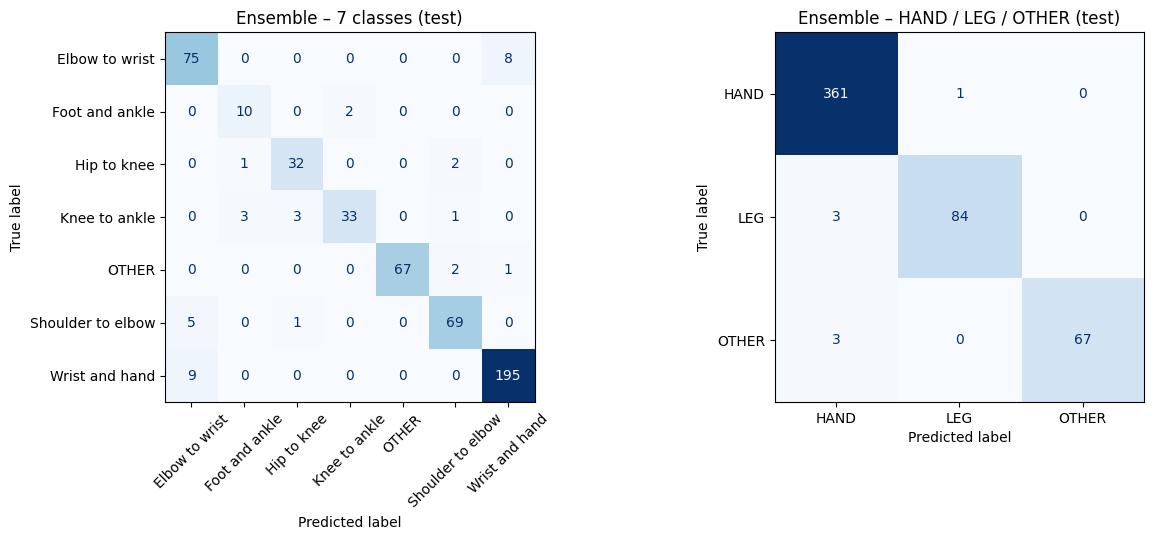

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

save_preds('ensemble_top2', 'val',  np.mean([probs[(n, 'val')]  for n in top2], axis=0))
save_preds('ensemble_top2', 'test', P_ens)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.5, 1]})
ConfusionMatrixDisplay(confusion_matrix(y, P_ens.argmax(1)), display_labels=[SHORT[c] for c in CLASSES]).plot(
    ax=ax[0], xticks_rotation=45, cmap='Blues', colorbar=False)
ax[0].set_title('Ensemble – 7 classes (test)')
ConfusionMatrixDisplay(confusion_matrix(ts, (P_ens @ M).argmax(1)), display_labels=SUPER_NAMES).plot(
    ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Ensemble – HAND / LEG / OTHER (test)')
plt.tight_layout(); plt.show()

## Summary – Model comparison + ensemble (test, 519 images)
| Model | HAND/LEG/OTHER acc | 7-class acc | 7-class macro-F1 | Size | ms/img (T4) |
|---|---|---|---|---|---|
| MobileNetV3-Large | 97.9% | 92.1% | 0.891 | 17 MB | 12.2 |
| EfficientNetV2-S | 94.4% | 86.5% | 0.812 | 82 MB | 18.4 |
| DeiT-Small | 98.5% | 93.6% | 0.920 | 87 MB | 5.6 |
| Ensemble DeiT + MobileNetV3 | 98.7% (95% CI 97.5–99.6) | 92.7% | 0.898 | 104 MB | ~18 |
- Same data, augmentation, epochs and settings for all models. Ensemble members chosen on VALIDATION (best two).
- Transformer (DeiT) = best single model. EfficientNetV2-S still improving at epoch 15 (under-trained in the shared budget; pretrained at 300–384 px).
- Ensemble vs DeiT: routing level fixes 2 / breaks 1 (LEG→HAND errors 3 vs 6 for MobileNetV3); 7-class fixes 3 / breaks 8.
  Gain within CI → not significant. Models disagree on 6.6% → possible uncertainty flag for human review.

In [ ]:
# ===== Chart for the presentation: training of the 3 models (reads saved files, no training) =====
from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt

OUT = Path('/content/drive/MyDrive/Research/outputs/model2')
NAMES  = {'mobilenetv3': 'MobileNetV3-Large (CNN)', 'efficientnetv2_s': 'EfficientNetV2-S (CNN)', 'deit_small': 'DeiT-Small (transformer)'}
COLORS = {'mobilenetv3': '#0F6FC6', 'efficientnetv2_s': '#A3ACB8', 'deit_small': '#063056'}
hist = {k: pd.read_csv(OUT / f'history_{k}.csv') for k in NAMES}

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k, h in hist.items():
    ax[0].plot(h.epoch, h.train_loss, marker='o', ms=4, lw=2, color=COLORS[k], label=NAMES[k])
    ax[1].plot(h.epoch, h.val_macro_f1, marker='o', ms=4, lw=2, color=COLORS[k], label=NAMES[k])
    b = h.val_macro_f1.idxmax()                                    # best epoch = the saved model
    ax[1].scatter(h.epoch[b], h.val_macro_f1[b], s=160, facecolors='none', edgecolors=COLORS[k], linewidths=2)
ax[0].set_title('Training loss (lower = better)', loc='left', fontsize=13)
ax[1].set_title('Validation macro-F1, 7 classes (higher = better; circle = saved best epoch)', loc='left', fontsize=13)
for a in ax:
    a.set_xlabel('epoch'); a.grid(alpha=0.25); a.spines[['top', 'right']].set_visible(False)
ax[0].set_yscale('log'); ax[1].legend(frameon=False, loc='lower right')
fig.suptitle('Model 2 – training of the three architectures (same data and settings)', x=0.01, ha='left',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'chart_model2_training_curves.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', OUT / 'chart_model2_training_curves.png')

In [ ]:
# ===== Chart for the presentation: model comparison incl. ensembles (reads model_comparison.csv) =====
from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
OUT = Path('/content/drive/MyDrive/Research/outputs/model2')
c = pd.read_csv(OUT / 'model_comparison.csv').set_index('model')
LABELS = {'mobilenetv3': 'MobileNetV3-Large', 'efficientnetv2_s': 'EfficientNetV2-S', 'deit_small': 'DeiT-Small',
          'ENS top-2': 'Ensemble DeiT + MobileNetV3 (chosen)', 'ENS all-3': 'Ensemble all 3'}
order = ['efficientnetv2_s', 'mobilenetv3', 'deit_small', 'ENS all-3', 'ENS top-2']
cols  = ['#0F6FC6' if m == 'ENS top-2' else '#A3ACB8' for m in order]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'wspace': 0.18})
for a, col, title, fmt, lim in [(ax[0], 'val_macroF1_7', 'Validation macro-F1 (used to choose)', '{:.3f}', (0.80, 0.95)),
                                (ax[1], 'test_acc_3', 'Test HAND/LEG/OTHER accuracy', '{:.1%}', (0.92, 1.0)),
                                (ax[2], 'test_macroF1_7', 'Test 7-class macro-F1', '{:.3f}', (0.78, 0.95))]:
    v = c.loc[order, col]
    for i, (x, colr) in enumerate(zip(v, cols)):                      # dot plot: fair when the axis does not start at 0
        a.hlines(i, lim[0], x, color='#E5E7EB', lw=2)
        a.scatter(x, i, s=150, color=colr, zorder=3, edgecolor='white', linewidth=2)
        a.text(x + (lim[1] - lim[0]) * 0.025, i, fmt.format(x), va='center', fontsize=11,
               fontweight='bold' if colr == '#0F6FC6' else 'normal')
    a.set_xlim(*lim); a.set_title(title, loc='left', fontsize=12); a.grid(axis='x', alpha=0.25)
    a.spines[['top', 'right', 'left']].set_visible(False); a.tick_params(axis='y', length=0)
    a.set_yticks(range(len(order))); a.set_yticklabels([LABELS[m] for m in order] if a is ax[0] else [])
fig.suptitle('Model 2 – comparison on the same data (519 test images); axes do not start at zero',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.savefig(OUT / 'chart_model2_comparison.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', OUT / 'chart_model2_comparison.png')